First five rows of the dataset:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373

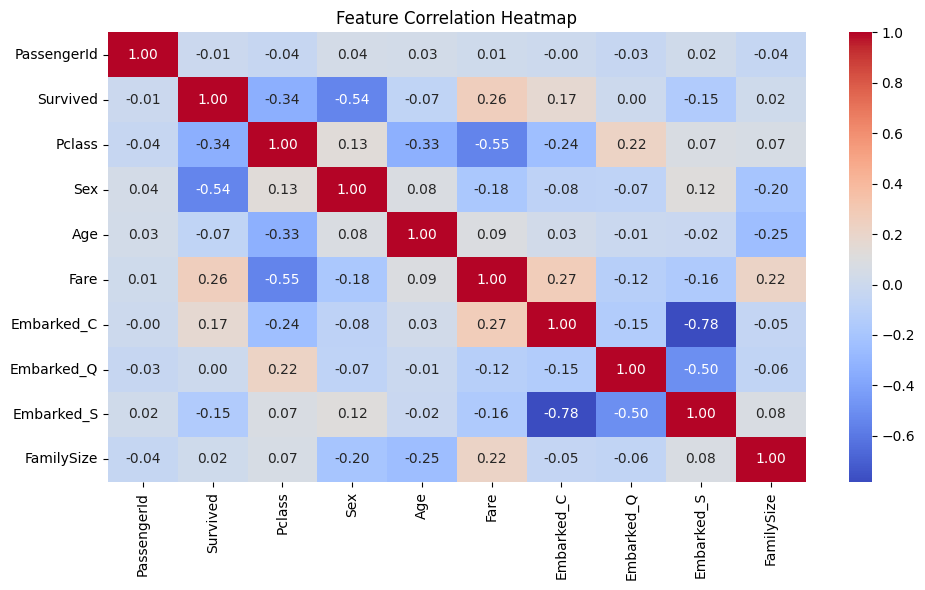


Training data: (712, 8)
Testing data: (179, 8)

Model Evaluation:
Accuracy: 0.7988826815642458
Precision: 0.7796610169491526
Recall: 0.6666666666666666
F1 Score: 0.71875


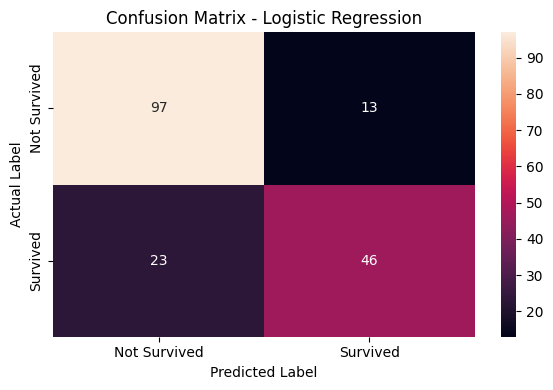


Misclassified Samples:
     PassengerId  Pclass  Sex        Age      Fare  FamilySize  Survived  \
553          554       3    1  22.000000    7.2250           1         1   
559          560       3    0  36.000000   17.4000           2         1   
279          280       3    0  35.000000   20.2500           3         1   
712          713       1    1  48.000000   52.0000           2         1   
455          456       3    1  29.000000    7.8958           1         1   
65            66       3    1  29.699118   15.2458           3         1   
489          490       3    1   9.000000   15.9000           3         1   
869          870       3    1   4.000000   11.1333           3         1   
165          166       3    1   9.000000   20.5250           3         1   
297          298       1    0   2.000000  151.5500           4         0   
564          565       3    0  29.699118    8.0500           1         0   
502          503       3    0  29.699118    7.6292           1  

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
df = pd.read_csv(r"C:\Users\DSL-189\Downloads\Titanic-Dataset.csv")
print("First five rows of the dataset:")
print(df.head())
print("\nDataset shape:")
print(df.shape)
print("\nMissing values:")
print(df.isnull().sum())
age_imputer = SimpleImputer(strategy="mean")
df["Age"] = age_imputer.fit_transform(df[["Age"]]).ravel()
embarked_imputer = SimpleImputer(strategy="most_frequent")
df["Embarked"] = embarked_imputer.fit_transform(df[["Embarked"]]).ravel()
df.drop(columns=["Cabin"], inplace=True)
df["Sex"] = df["Sex"].map({"female": 0, "male": 1})
df = pd.get_dummies(df, columns=["Embarked"], dtype=int)
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df.drop(columns=["Name", "Ticket", "SibSp", "Parch"], inplace=True)
correlation_matrix = df.corr()
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()
X = df.drop(columns=["Survived", "PassengerId"])
y = df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("\nModel Evaluation:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"],
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()
error_analysis = X.copy()

test_results = df.loc[
    y_test.index,
    ["PassengerId", "Pclass", "Sex", "Age", "Fare", "FamilySize", "Survived"],
].copy()

test_results["Predicted"] = y_pred
misclassified = test_results[test_results["Survived"] != test_results["Predicted"]]

print("\nMisclassified Samples:")
print(misclassified)
print("\nTotal Misclassified Samples:", len(misclassified))
